# Locating a sound wavefront with Dleto

`CC-BY 2026 Brooksbank, Kassabov, Wilson`

The [Sphere Lab](SphereLab.ipynb) showed how Dleto detects a sphere hidden in a tensor.  This notebook applies the same ideas to a sphere that nature made: the wavefront of a sound pulse, recorded on a three-dimensional grid of microphone positions in a real room.

We use the *3D Meshgrid Room Impulse Response Dataset* of Yoichi Haneda and Yi Ren (University of Electro-Communications, Tokyo).  A loudspeaker emits a test pulse and the response is recorded at every point of a $48\times 51\times 26$ grid with 2 cm spacing, 63,648 positions in all.  Freezing the recording at one instant gives a three-way array whose large entries lie on a spherical shell centered on the loudspeaker.  That is the kind of pattern Dleto's chisels are built to detect, and we will use it to

 * find the wavefront's radius and the loudspeaker's position from the tensor alone,
 * tell from the tensor alone whether a wavefront is passing through the grid, and
 * recover the order of the microphones along each axis after that order has been thrown away.

Along the way we meet what measured data does to the clean story of the Sphere Lab.

> **Data.** Y. Haneda and Y. Ren, *3D Meshgrid Room Impulse Response Dataset (part I)*, Zenodo, 2025, [doi:10.5281/zenodo.17051811](https://doi.org/10.5281/zenodo.17051811), CC BY 4.0.  Described in Y. Haneda and Y. Ren, "3D mesh grid room impulse responses measured with a linear microphone array and suppression of frame reflections," ICASSP 2026.  Project page: [yh-audio.github.io/meshgrid-ir](https://yh-audio.github.io/meshgrid-ir.html).

> **Disclaimer.** This notebook illustrates Dleto's algorithms on a real data set.  It is not a treatment of room acoustics, and nothing here should be read as an acoustic analysis of the measured room.

---

 1. [Setting up](#1.-Setting-up)
 2. [The data](#2.-The-data)
 3. [A wavefront as a tensor](#3.-A-wavefront-as-a-tensor)
 4. [The surface law: locating the loudspeaker](#4.-The-surface-law:-locating-the-loudspeaker)
 5. [Derivations of measured data](#5.-Derivations-of-measured-data)
 6. [Recovering the order of the microphones](#6.-Recovering-the-order-of-the-microphones)
 7. [Going further](#7.-Going-further)

## 1. Setting up

This assumes you have cloned the full [Git repository](https://github.com/thetensor-space/OpenDleto) and launched the notebook from its `labs/` folder.  Installation instructions are in [Installing Dleto](../docs/Installing-Dleto.md).  The project environment includes `HDF5`, which reads the dataset's files.

In [1]:
using Pkg
Pkg.activate("../")        # the OpenDleto project
using ITensors, Plots, HDF5, Downloads, Random, Statistics, LinearAlgebra, Printf
using Dleto

  Activating project at `~/CODE/OpenDleto`


Loading Dleto Plots Extension


## 2. The data

The dataset is published in four files, one per loudspeaker position, each about 1 GB.  We use loudspeaker 1.  The next cell downloads the file into `labs/data/meshgrid-ir/` the first time it runs (this takes a few minutes) and is skipped afterwards.  The folder is excluded from version control.

In [2]:
datadir  = joinpath("data", "meshgrid-ir")
datafile = joinpath(datadir, "A_ir_16k_sp1.h5")
if !isfile(datafile)
    mkpath(datadir)
    println("Downloading 1 GB from Zenodo ...")
    Downloads.download("https://zenodo.org/records/17051811/files/A_ir_16k_sp1.h5?download=1", datafile)
end
println(filesize(datafile) ÷ 2^20, " MB")

971 MB


The file holds two arrays and a handful of attributes.  `rir` is the *room impulse response*: one column per microphone position, 4000 samples long at 16 kHz (a quarter of a second).  `grid` lists the coordinates of the positions in meters, relative to the first position; they are ordered with $x$ varying fastest, then $y$, then $z$, which is also the order Julia uses to store a three-way array.

In [3]:
h5 = h5open(datafile, "r")
fs       = read_attribute(h5, "fs")[1]                   # sampling rate, Hz
fulldims = Tuple(read_attribute(h5, "grid_dimensions"))   # (48, 51, 26)
speaker  = read_attribute(h5, "sp_pos") .- read_attribute(h5, "mic_array_pos")  # loudspeaker relative to the grid origin (m)
grid     = read(h5["grid"])                                # 63648 x 3 coordinates (m)
rir      = h5["rir"]                                       # 4000 x 63648, read lazily

println("sampling rate      : $(fs) Hz")
println("grid               : $(fulldims) positions at $(grid[2,1]) m spacing")
println("grid extent (m)    : ", Tuple(round(Float64(maximum(grid[:, j])); digits=2) for j in 1:3))
println("loudspeaker (m)    : ", Tuple(round.(Float64.(speaker); digits=2)))
println("impulse responses  : $(size(rir, 2)) of length $(size(rir, 1)) samples ($(size(rir,1)/fs) s)")

sampling rate      : 16000.0 Hz
grid               : (48, 51, 26) positions at 0.02 m spacing
grid extent (m)    : (0.94, 1.0, 0.5)
loudspeaker (m)    : (1.8, -2.0, 0.31)
impulse responses  : 63648 of length 4000 samples (0.25 s)


Here is the response at the first grid position: silence, then the direct sound arriving from the loudspeaker a few milliseconds in, then a long tail of reflections from the walls, floor and ceiling.

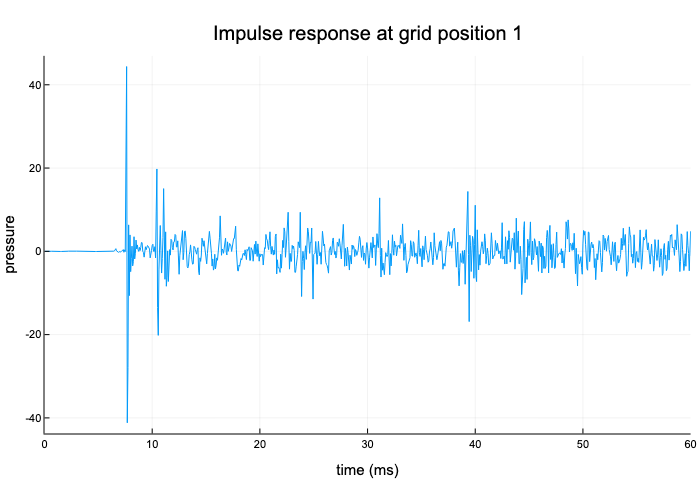

In [4]:
ir = rir[:, 1]
Plots.plot(1000 .* (0:length(ir)-1) ./ fs, ir; xlabel="time (ms)", ylabel="pressure", legend=false,
     title="Impulse response at grid position 1", size=(800, 300), xlims=(0, 60))

The direct sound reaches each position after travelling the distance from the loudspeaker at the speed of sound, so the sample at which the response peaks should be a linear function of that distance.  We check this on a sample of positions, and in doing so calibrate the effective speed of sound and the small timing offset of the measurement system.  Both are needed later to say which sphere the wavefront occupies at a given instant.

arrival sample ≈ 45.67 × distance + -1.31   ⇒   speed of sound 350 m/s, offset -1.3 samples


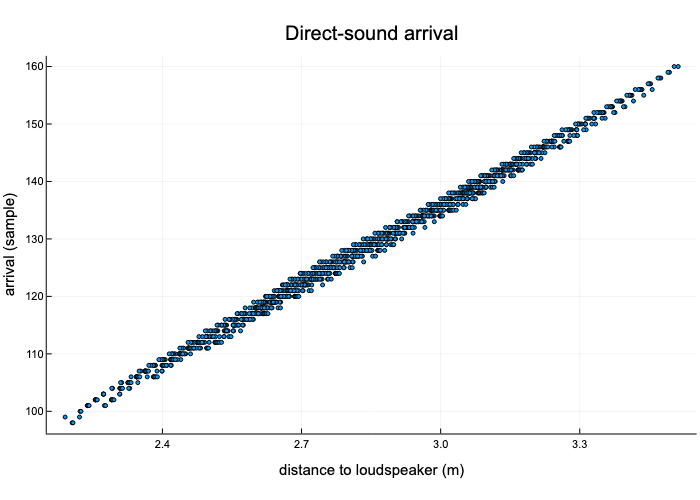

In [5]:
positions = 1:50:size(grid, 1)
distance  = [norm(grid[i, :] .- speaker) for i in positions]
arrival   = [argmax(abs.(rir[:, i])) for i in positions]

coef  = [distance ones(length(distance))] \ arrival        # arrival ≈ coef[1]*distance + coef[2]
c_eff = fs / coef[1];  offset = coef[2]
@printf("arrival sample ≈ %.2f × distance + %.2f   ⇒   speed of sound %.0f m/s, offset %.1f samples\n", coef[1], coef[2], c_eff, offset)

Plots.scatter(distance, arrival; xlabel="distance to loudspeaker (m)", ylabel="arrival (sample)", legend=false,
        title="Direct-sound arrival", markersize=2, size=(800, 300))

## 3. A wavefront as a tensor

Fix an instant $t$ (a sample number).  Row $t$ of `rir`, reshaped to the grid, is a $48\times 51\times 26$ array: a snapshot of the pressure field.  The direct sound occupies the sphere of radius
$$r(t) = c_{\mathrm{eff}}\,(t-\mathrm{offset})/f_s$$
around the loudspeaker, so the large entries of the snapshot lie on the intersection of that sphere with the box of microphones.

**Resolution.**  The full grid is a tensor with 63,648 entries.  The derivation computations behind `stratify` then become dense linear-algebra problems with thousands of unknowns, which take minutes per call on a laptop.  Reading every second grid point instead (`stride = 2`, a 4 cm grid of $24\times 26\times 13$) keeps every step in this notebook below a few seconds while leaving the wavefront a few cells thick.  Lower `stride` to 1 once you are familiar with the notebook and have time to spare.

We read the samples we will need in one go, then define two snapshots.  `pressure(t)` is the raw field.  The measured pulse rings for several samples either side of its peak, so a pressure snapshot is a stack of shells of alternating sign.  `energy(t)` sums the squared pressure over a short window around $t$, which merges the ringing into a single positive shell and is the tensor we use for most of the notebook.  Both are scaled so that the largest entry is 1.

In [6]:
stride = 2
sel  = [1:stride:fulldims[1], 1:stride:fulldims[2], 1:stride:fulldims[3]]
dims = Tuple(length.(sel))
xs = unique(grid[:, 1])[sel[1]];  ys = unique(grid[:, 2])[sel[2]];  zs = unique(grid[:, 3])[sel[3]]

tmin, tmax = 80, 220                                   # the direct sound crosses the grid within this window
block = Float64.(rir[tmin:tmax, :])                     # 141 x 63648
field(t) = reshape(block[t - tmin + 1, :], fulldims...)[sel...]

radius(t)   = c_eff * (t - offset) / fs
pressure(t) = (P = field(t); P ./ maximum(abs, P))
energy(t; halfwidth = 3) = (E = sum(field(t + τ).^2 for τ in -halfwidth:halfwidth); E ./ maximum(E))

dims

(24, 26, 13)

We take an instant at which the wavefront is passing through the middle of the grid.  `plot_tensor` draws the entries above a threshold with marker size proportional to magnitude (and shows at most the 1000 largest).  The loudspeaker is off to the side and roughly level with the grid, so the sphere meets the box as a curved sheet standing on edge; its curvature is visible in the energy picture.

wavefront radius at sample 131: 2.90 m;  the grid spans 2.18 .. 3.51 m from the loudspeaker


┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257
┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257


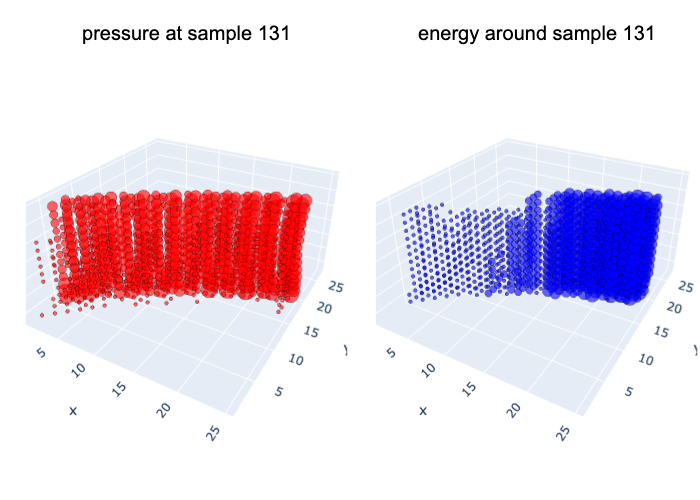

In [7]:
t₀ = 131
@printf("wavefront radius at sample %d: %.2f m;  the grid spans %.2f .. %.2f m from the loudspeaker\n", t₀, radius(t₀),
        minimum(norm(grid[i, :] .- speaker) for i in 1:size(grid, 1)), maximum(norm(grid[i, :] .- speaker) for i in 1:size(grid, 1)))

p1 = plot_tensor(pressure(t₀), 0.1; title="pressure at sample $(t₀)", color=:red)
p2 = plot_tensor(energy(t₀),   0.1; title="energy around sample $(t₀)", color=:blue)
Plots.plot(p1, p2; layout=(1, 2), size=(1000, 420))

## 4. The surface law: locating the loudspeaker

In the Sphere Lab the cleaner experiment sampled the sphere in a special way: each axis carried values $u_i$, $v_j$, $w_k$ and the tensor was supported where $u_i + v_j + w_k \approx 0$.  Nature has done the same here.  With the loudspeaker at $(a,b,c)$ and the wavefront at radius $r$, the energy is large where
$$(x_i - a)^2 + (y_j - b)^2 + (z_k - c)^2 - r^2 \approx 0,$$
so the choice $u_i = (x_i-a)^2$, $v_j = (y_j-b)^2$, $w_k = (z_k-c)^2 - r^2$ puts the wavefront in exactly the form Dleto looks for.  Dleto's `distSurfaceTensor` measures how far a tensor is from being supported on such a surface: 0 means the tensor lies on it, and a random tensor gives the baseline.

In [8]:
x, y, z = Index(dims[1], "x"), Index(dims[2], "y"), Index(dims[3], "z")
𝔼 = ITensor(energy(t₀), x, y, z)                       # \bbE[TAB] gives 𝔼

U(a)    = (xs .- a).^2
V(b)    = (ys .- b).^2
W(c, r) = (zs .- c).^2 .- r^2

@printf("distance from the surface law:  wavefront %.4f    random tensor %.4f\n",
        distSurfaceTensor(𝔼, U(speaker[1]), V(speaker[2]), W(speaker[3], radius(t₀))),
        distSurfaceTensor(ITensor(randn(dims...), x, y, z), U(speaker[1]), V(speaker[2]), W(speaker[3], radius(t₀))))

distance from the surface law:  wavefront 0.0047    random tensor 0.4469


Now suppose we did *not* know where the loudspeaker was, or how far the wavefront had travelled.  The surface law turns the question around: scan a parameter and look for the value at which the tensor comes closest to obeying the law.  We scan the radius and each coordinate of the loudspeaker in turn, holding the others at their true values.

best radius 2.90 m (true 2.90)
best loudspeaker x 1.80 m (true 1.80),  y -2.00 m (true -2.00),  z 0.25 m (true 0.31)


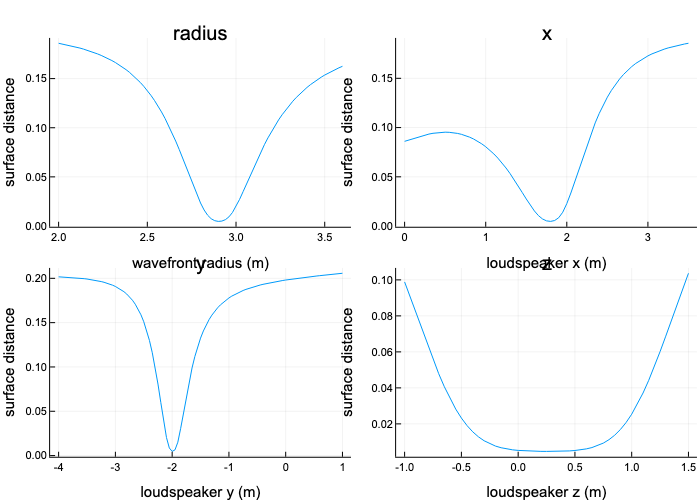

In [9]:
a₀, b₀, c₀, r₀ = speaker[1], speaker[2], speaker[3], radius(t₀)
scan(f, values) = [f(v) for v in values]

rs = 2.0:0.02:3.6;    d_r = scan(r -> distSurfaceTensor(𝔼, U(a₀), V(b₀), W(c₀, r)),  rs)
as = 0.0:0.05:3.5;    d_a = scan(a -> distSurfaceTensor(𝔼, U(a),  V(b₀), W(c₀, r₀)), as)
bs = -4.0:0.05:1.0;   d_b = scan(b -> distSurfaceTensor(𝔼, U(a₀), V(b),  W(c₀, r₀)), bs)
cs = -1.0:0.05:1.5;   d_c = scan(c -> distSurfaceTensor(𝔼, U(a₀), V(b₀), W(c,  r₀)), cs)

@printf("best radius %.2f m (true %.2f)\n", rs[argmin(d_r)], r₀)
@printf("best loudspeaker x %.2f m (true %.2f),  y %.2f m (true %.2f),  z %.2f m (true %.2f)\n",
        as[argmin(d_a)], a₀, bs[argmin(d_b)], b₀, cs[argmin(d_c)], c₀)

Plots.plot(Plots.plot(rs, d_r; xlabel="wavefront radius (m)", title="radius"),
     Plots.plot(as, d_a; xlabel="loudspeaker x (m)", title="x"),
     Plots.plot(bs, d_b; xlabel="loudspeaker y (m)", title="y"),
     Plots.plot(cs, d_c; xlabel="loudspeaker z (m)", title="z");
     layout=(2, 2), size=(900, 600), legend=false, ylabel="surface distance")

The radius and the $x$ and $y$ coordinates are pinned down sharply by a $24\times 26\times 13$ tensor of energies, with no knowledge of acoustics beyond "the wavefront is a sphere".  The $z$ scan is different: its valley is wide and flat.  The loudspeaker is nearly level with the grid, and moving it up or down by a few tens of centimeters barely changes which microphones it is equidistant from.  Keep this in mind for Section 6, where the same geometry limits what stratification can recover.

The law also works as a detector.  Evaluating it at every instant, with the radius the wavefront *should* have at that instant, tells us when the direct sound is inside the grid: the distance is near zero while it crosses and jumps once it has left and only reflections remain.

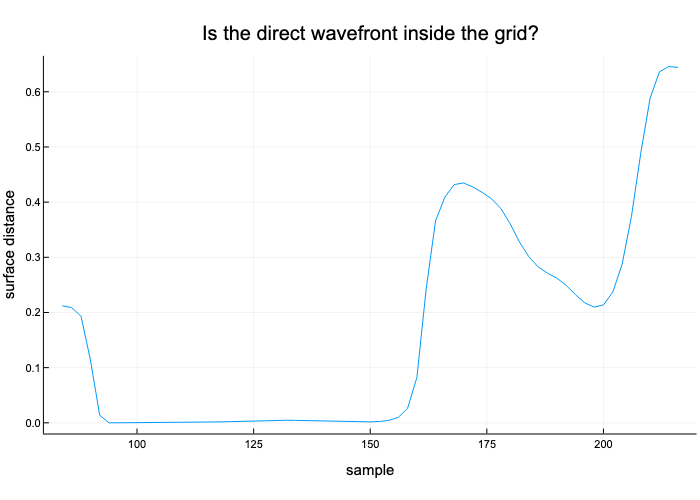

In [10]:
ts  = (tmin + 4):2:(tmax - 4)
d_t = [distSurfaceTensor(ITensor(energy(t), x, y, z), U(a₀), V(b₀), W(c₀, radius(t))) for t in ts]
Plots.plot(ts, d_t; xlabel="sample", ylabel="surface distance", legend=false, size=(800, 300),
     title="Is the direct wavefront inside the grid?")

┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257
┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257


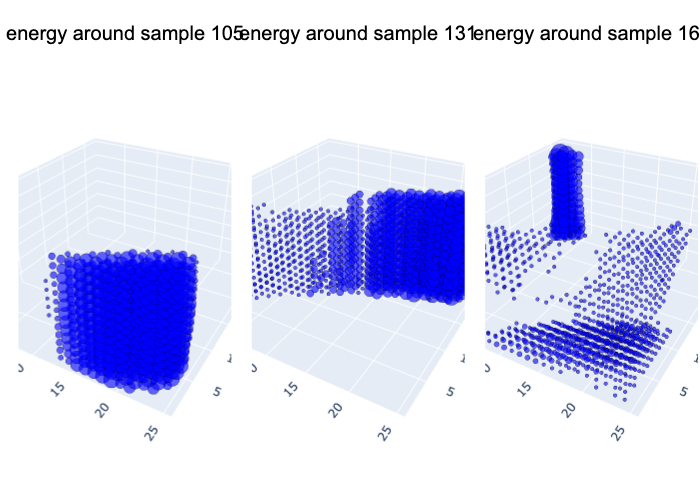

In [11]:
plots = [plot_tensor(energy(t), 0.1; title="energy around sample $(t)", color=:blue) for t in (105, 131, 160)]
Plots.plot(plots...; layout=(1, 3), size=(1400, 420))

At sample 105 the wavefront has just entered the corner of the grid nearest the loudspeaker; at 131 it is crossing the middle; by 160 it has left, and what remains is the first reflections (spheres centered on *image* loudspeakers behind the walls), which obey a different surface law.

## 5. Derivations of measured data

The reason the surface law matters to Dleto is that a tensor obeying it is (nearly) annihilated by the triple of diagonal matrices $(\mathrm{diag}(u), \mathrm{diag}(v), \mathrm{diag}(w))$: applying one to each axis and summing gives $\sum_{ijk}(u_i+v_j+w_k)\,\Gamma_{ijk}$, which vanishes when $\Gamma$ is supported on the surface.  Such a triple is a *derivation* of $\Gamma$.  `stratify` works by finding derivations and changing coordinates to put them in a canonical form.  Every tensor has two trivial derivations (rescale one axis, counter-rescale another), so "more than two derivations" is Dleto's signal that structure is present.

With measured data nothing is annihilated exactly: the shell has a thickness, slices of the grid carry very different amounts of energy, and reflections and noise are present.  The three geometric derivations are *near*-derivations, and they are not the only ones.  We can look at the smallest singular values of the operator whose null space is the derivation space.  (This cell reaches a little below Dleto's public interface to build that operator; `UniversalOp()` allows any matrix on each axis, `DiagonalOp()` only diagonal ones.)

In [12]:
function derivation_spectrum(Γ::ITensor, ops; n = 8)
    ch = UniversalChisel(3)
    Ω  = IndTransverseOps(collect(inds(Γ)), ops)
    eng = engaged(ch);  Ωr, _ = reduceByEngaged(Ω, eng, Float64)
    L, _ = Dleto.sylvesterLM(Ωr, Matrix{Float64}(ch[:, eng]), Γ)
    σ = svdvals(Matrix(L))
    return reverse(σ[end-n+1:end]) ./ σ[1]                 # the n smallest, relative to the largest
end

for (name, ops) in (("any matrices  ", UniversalOp()), ("diagonal only ", DiagonalOp()))
    σ = derivation_spectrum(𝔼, ops)
    print(name, ": ");  foreach(s -> @printf(" %.0e", s), σ);  println()
end

any matrices  :  3e-18 6e-18 1e-11 1e-11 1e-11 1e-11 1e-11 1e-11
diagonal only :  3e-17 6e-17 6e-10 5e-09 7e-08 7e-06 2e-05 5e-05


Two values are zero to machine precision: the trivial derivations.  After them there is no clear gap: when any matrices are allowed there is a plateau of near-derivations, and even among diagonal ones the values climb gradually.  Dleto's default rule certifies a null space by looking for a clear gap in this spectrum, and its honest answer here is "2": measured data has no exact sparsity pattern.  To work with the near-derivations we ask for a fixed number of them with the keyword `nd`.

In [13]:
for nd in (-1, 3, 5)
    ders = der(𝔼; nd=nd, tol=1e-3)
    println("der(𝔼; nd=$(nd)) returned $(length(ders)) derivations")
end

Using SVDSolver...
Converting LinearMap to Matrix for SVD...


┌ Info: der: nullity 2 certified (rule :gap), cut at the Float64 precision floor 2.220446049250313e-14 (relative) -- a near-derivation hidden below that floor would look identical. Values around the cut: [2.7863541158615243e-18, 3.462549722334304e-16] | [1.1693252250654082e-11, 1.2750248505909201e-11, 1.3167397396402684e-11]
└ @ Dleto /Users/algeboy/CODE/OpenDleto/src/solvers/NullSolvers.jl:658


der(𝔼; nd=-1) returned 2 derivations
Using SVDSolver...
Converting LinearMap to Matrix for SVD...
der(𝔼; nd=3) returned 3 derivations
Using SVDSolver...
Converting LinearMap to Matrix for SVD...
der(𝔼; nd=5) returned 5 derivations


## 6. Recovering the order of the microphones

In the Sphere Lab the sphere was hidden by a random invertible change of coordinates on each axis and recovered by `stratify`.  On this data that experiment is only partly successful, for the reason the spectrum just showed: among all matrices there is a crowd of near-derivations, and a random combination of a few of them recovers a blurred picture.  (It is an instructive experiment; see Section 7.)

Dleto's chisels let us say what *shape* of derivation we are looking for.  The geometric derivations are diagonal, so we restrict the operator space to `DiagonalOp()`: then a derivation is just a triple of vectors $(u, v, w)$, and stratifying along it means *sorting each axis* by the entries of its vector.  The structure this can recover is the order of the microphones along each axis, so that is what we hide: we shuffle the labels of the grid positions along $x$, $y$ and $z$ independently, which turns the sheet into confetti, and ask Dleto to put them back.  We use `nd = 3`: the two trivial derivations plus one geometric one.

In [14]:
# A random permutation of each axis, as Dleto transforms.
function shuffle_axes(Γ::ITensor)
    Ps = ITensor[]
    for i in inds(Γ)
        n = ITensors.dim(i);  M = zeros(n, n)
        for (row, col) in enumerate(randperm(n));  M[row, col] = 1;  end
        push!(Ps, ITensor(M, i, sim(i)))
    end
    return Γ * Ps, Ps
end

Random.seed!(4)
𝔼_sh, Ps = shuffle_axes(𝔼)
@assert isapprox(𝔼 * Ps, 𝔼_sh)

Ω  = IndTransverseOps(collect(inds(𝔼_sh)), DiagonalOp())   # look for diagonal derivations only
ch = UniversalChisel(3)
@time 𝔼_strat, Zs = stratify(Ω, ch, 𝔼_sh; nd=3, tol=1e-3)
# `stratify` returns its result on the frame it was given, so compare entries:
lhs = 𝔼_sh * Zs;  @assert isapprox(Array(lhs, inds(lhs)...), Array(𝔼_strat, inds(𝔼_strat)...))

Using SVDSolver...
Converting LinearMap to Matrix for SVD...


┌ Info: Found 3 derivations for stratification.
└ @ Dleto /Users/algeboy/CODE/OpenDleto/src/Densors.jl:253


  2.177370 seconds (17.06 M allocations: 897.237 MiB, 16.42% gc time, 94.80% compilation time)


┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257
┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257
┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257


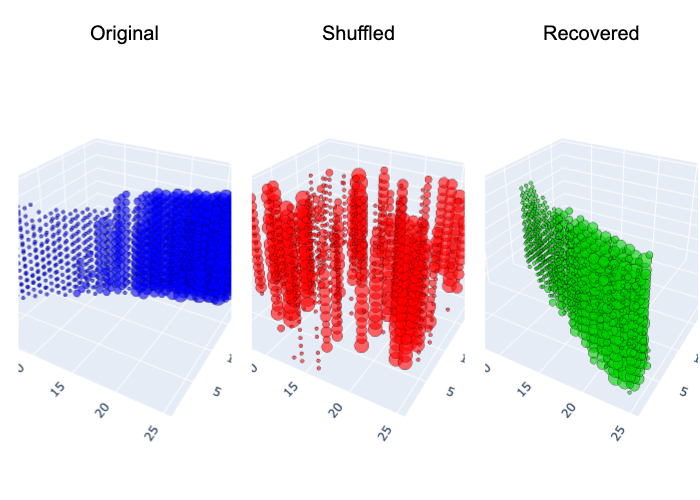

In [15]:
normalized(T::ITensor) = (A = Array(T, inds(T)...); A ./ maximum(abs, A))

p1 = plot_tensor(normalized(𝔼), 0.1;       title="Original",  color=:blue)
p2 = plot_tensor(normalized(𝔼_sh), 0.1;    title="Shuffled",  color=:red)
p3 = plot_tensor(normalized(𝔼_strat), 0.1; title="Recovered", color=:green)
Plots.plot(p1, p2, p3; layout=(1, 3), size=(1400, 420))

The sheet is back.  To see exactly what was recovered, compose the shuffle with the stratification: for each axis this gives a matrix from original positions to recovered positions, and if the order was recovered perfectly it is a permutation that is monotone (increasing or decreasing) in the original index.

axis x: rank correlation between original and recovered order 1.00
axis y: rank correlation between original and recovered order 0.60
axis z: rank correlation between original and recovered order 0.77


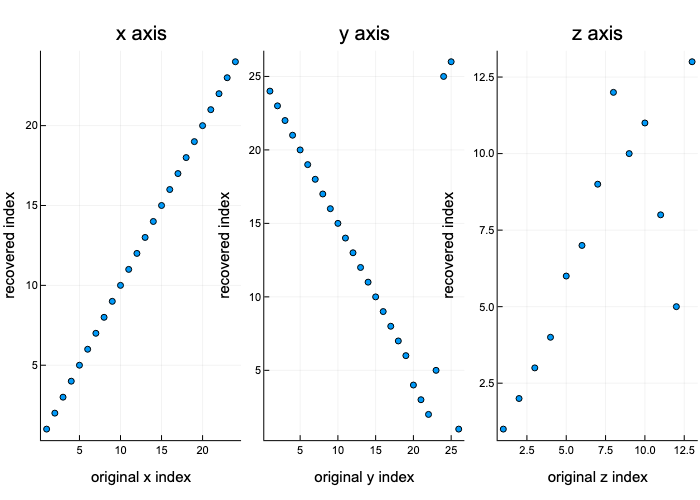

In [16]:
# the total transform applied to one axis, as a matrix: original index -> recovered index
function axis_transform(a::Index, stages...)
    T = nothing
    for mats in stages
        M = only(filter(t -> hasind(t, a), mats))
        a = only(filter(i -> i != a, inds(M)))
        T = T === nothing ? M : T * M
    end
    return Array(T, inds(T)...)
end
recovered_position(M) = [argmax(abs.(M[row, :])) for row in axes(M, 1)]

plots = []
for (name, ax) in zip(("x", "y", "z"), (x, y, z))
    pos = recovered_position(axis_transform(ax, Ps, Zs))
    @printf("axis %s: rank correlation between original and recovered order %.2f\n", name, abs(cor(sortperm(sortperm(pos)), 1:length(pos))))
    push!(plots, Plots.scatter(1:length(pos), pos; xlabel="original $(name) index", ylabel="recovered index", title="$(name) axis", legend=false, markersize=3))
end
Plots.plot(plots...; layout=(1, 3), size=(1200, 350))

Along $x$ the order comes back exactly.  Along $y$ it comes back reversed (stratification sorts by the derivation's entries, and it cannot know the sign), except for the last few positions: those are the slices farthest from the loudspeaker, which the wavefront has not reached at this instant, so they carry almost no energy and nothing in the tensor says where they belong.  Along $z$ the order is largely right but a few heights are swapped.  This is the flat valley of the $z$ scan in Section 4 again: the loudspeaker is nearly level with the grid, so $(z_k - c)^2$ varies little across the grid, and two heights on either side of the loudspeaker's are nearly indistinguishable to the wavefront.  Compare the "octant" discussion in the Sphere Lab: Dleto orders points by the eigenvalues of a derivation, and points with equal eigenvalues cannot be separated.

## 7. Going further

Some things to try, roughly in order of cost.

 * **Change the instant.**  Any `t` between about 97 and 150 has the direct wavefront inside the grid (Section 4).  Early on, only a corner of the grid carries energy and more of the far slices are undetermined; later, reflections start to compete.
 * **Change `nd`.**  With `nd = 5` or more, extra near-derivations are mixed in.  Watch the rank correlations.
 * **Use the pressure snapshot** instead of the energy.  The surface law still holds; the shuffled-grid recovery is noisier because the ringing spreads the energy over several shells.
 * **The Sphere Lab experiment.**  Hide the wavefront with `randomize_tensor` (a general invertible change of coordinates), remove redundancy with `nondeg`, and call `stratify(…; nd=5)` with the default operator space.  Then compare, as above, the composed transforms with a permutation.  On this data expect a partial recovery: the picture concentrates but does not become a sheet, and the correlations are far from 1.  The next cell runs it.
 * **Change `stride`.**  `stride = 1` is the full 2 cm grid.  The dense solver then needs minutes per call.  Loading `Arpack` lets Dleto's `AutoSolver` use an iterative eigensolver, which is fast on the exact sphere of the Sphere Lab, but on measured data without a spectral gap it may fail to converge, which is itself instructive.
 * **Other loudspeakers.**  Files `sp2` to `sp4` move the source along $x$; the scans of Section 4 should find it.
 * **Space and time together.**  Fixing a height $z_0$ and taking a window of samples gives a tensor $\Gamma[x, y, t]$ supported where $(x-a)^2 + (y-b)^2 + (z_0-c)^2 - r(t)^2 \approx 0$, again of the form $u_i + v_j + w_k \approx 0$, now with a *time* axis.  Build it from `block` and check the surface law.

Using SVDSolver...
Converting LinearMap to Matrix for SVD...


┌ Info: Found 5 derivations for stratification.
└ @ Dleto /Users/algeboy/CODE/OpenDleto/src/Densors.jl:253


  0.962361 seconds (9.18 M allocations: 1.622 GiB, 8.53% gc time, 5.99% compilation time)
axis x: rank correlation 0.76
axis y: rank correlation 0.11
axis z: rank correlation 0.31


┌ Warning: More than 1,000 viewable entries, plotting only the largest points.
└ @ DletoPlotsExt /Users/algeboy/CODE/OpenDleto/ext/DletoPlotsExt.jl:257


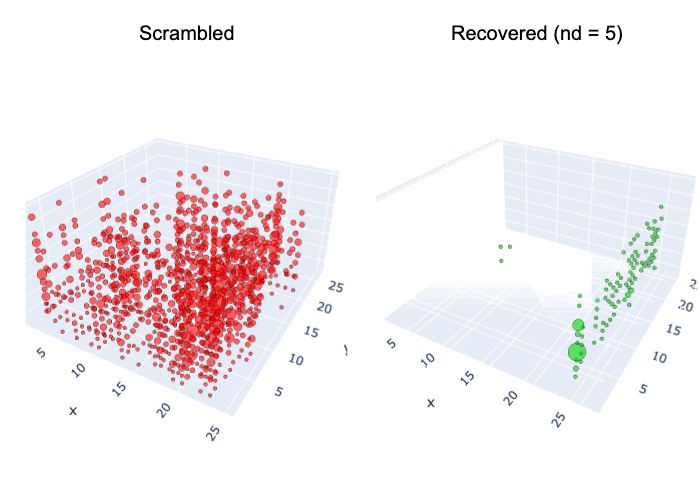

In [17]:
𝔼_rn, Xs = randomize_tensor(𝔼)
𝔼_nd, Ys = nondeg(𝔼_rn)
@time 𝔼_strat2, Zs2 = stratify(𝔼_nd; nd=5, tol=1e-3)

for (name, ax) in zip(("x", "y", "z"), (x, y, z))
    pos = recovered_position(axis_transform(ax, Xs, Ys, Zs2))
    @printf("axis %s: rank correlation %.2f\n", name, abs(cor(sortperm(sortperm(pos)), 1:length(pos))))
end
p1 = plot_tensor(normalized(𝔼_rn), 0.1;     title="Scrambled", color=:red)
p2 = plot_tensor(normalized(𝔼_strat2), 0.1; title="Recovered (nd = 5)", color=:green)
Plots.plot(p1, p2; layout=(1, 2), size=(1000, 420))

In [18]:
close(h5)